## **Books Market Analysis- End-to-End Data Analytics Project**

**Website:** Books to Scrape — https://books.toscrape.com/

In [1]:
import re, time
from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

BASE_HOME = "https://books.toscrape.com/"
BASE_PAGE = "https://books.toscrape.com/catalogue/page-{}.html"
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/154.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9"
}
session=requests.Session()
session.headers.update(HEADERS)

r=session.get(BASE_HOME,timeout=20)
print("Status code:",r.status_code)
home_soup=BeautifulSoup(r.text,"html.parser")
current=home_soup.select_one(".current")
m=re.search(r"of\s+(\d+)",current.get_text(" ",strip=True),re.I) if current else None
TOTAL_PAGES=int(m.group(1)) if m else 50
print("Total pages:",TOTAL_PAGES)

Status code: 200
Total pages: 50


# **1.Multi-Page Web Scraping**

In [2]:
def get_page(page_no):
    url=BASE_PAGE.format(page_no)
    res=session.get(url,timeout=20)
    res.raise_for_status()
    return BeautifulSoup(res.text,"html.parser")

all_data=[]
for page in range(1,TOTAL_PAGES+1):
    soup=get_page(page)
    for book in soup.select("article.product_pod"):
        all_data.append({
            "Title":book.select_one("h3 a")["title"],
            "Price_Raw":book.select_one("p.price_color").get_text(" ",strip=True),
            "Availability":book.select_one("p.availability").get_text(" ",strip=True),
            "Rating_Raw":book.select_one("p.star-rating")["class"][-1],
            "Page":page
        })
    print(f"Page {page}/{TOTAL_PAGES} -> {len(all_data)} books")
    time.sleep(0.5)

raw_df=pd.DataFrame(all_data)
print("Final shape:",raw_df.shape)
raw_df.to_csv("scraped_books.csv",index=False)
display(raw_df.head())

Page 1/50 -> 20 books
Page 2/50 -> 40 books
Page 3/50 -> 60 books
Page 4/50 -> 80 books
Page 5/50 -> 100 books
Page 6/50 -> 120 books
Page 7/50 -> 140 books
Page 8/50 -> 160 books
Page 9/50 -> 180 books
Page 10/50 -> 200 books
Page 11/50 -> 220 books
Page 12/50 -> 240 books
Page 13/50 -> 260 books
Page 14/50 -> 280 books
Page 15/50 -> 300 books
Page 16/50 -> 320 books
Page 17/50 -> 340 books
Page 18/50 -> 360 books
Page 19/50 -> 380 books
Page 20/50 -> 400 books
Page 21/50 -> 420 books
Page 22/50 -> 440 books
Page 23/50 -> 460 books
Page 24/50 -> 480 books
Page 25/50 -> 500 books
Page 26/50 -> 520 books
Page 27/50 -> 540 books
Page 28/50 -> 560 books
Page 29/50 -> 580 books
Page 30/50 -> 600 books
Page 31/50 -> 620 books
Page 32/50 -> 640 books
Page 33/50 -> 660 books
Page 34/50 -> 680 books
Page 35/50 -> 700 books
Page 36/50 -> 720 books
Page 37/50 -> 740 books
Page 38/50 -> 760 books
Page 39/50 -> 780 books
Page 40/50 -> 800 books
Page 41/50 -> 820 books
Page 42/50 -> 840 books
Page 

,Title,Price_Raw,Availability,Rating_Raw,Page
0,A Light in the Attic,Â£51.77,In stock,Three,1
1,Tipping the Velvet,Â£53.74,In stock,One,1
2,Soumission,Â£50.10,In stock,One,1
3,Sharp Objects,Â£47.82,In stock,Four,1
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five,1


# **2.Data Quality Checks**

In [3]:
print("Shape:",raw_df.shape)
raw_df.info()
print("\nMissing values:")
display(raw_df.isnull().sum())
print("Duplicate rows:",raw_df.duplicated().sum())

Shape: (1000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price_Raw     1000 non-null   object
 2   Availability  1000 non-null   object
 3   Rating_Raw    1000 non-null   object
 4   Page          1000 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 39.2+ KB

Missing values:


,0
Title,0
Price_Raw,0
Availability,0
Rating_Raw,0
Page,0


Duplicate rows: 0


# **3.Data Cleaning - 7 Regex Tasks**
1.Price extraction

2.Stock-count extrction

3.In-stock extraction

4.Rating-number extraction

5.Page-number extraction

6.Title whitespace normalization

7.Category normalization

In [4]:
df=raw_df.copy()

# Regex 1: numeric price
df["Price"]=df["Price_Raw"].str.extract(r"([0-9]+(?:\.[0-9]+)?)",expand=False).astype(float)

# Regex 2: stock count
df["Stock_Count"]=pd.to_numeric(
    df["Availability"].str.extract(r"(\d+)\s+available",expand=False),
    errors="coerce"
)

# Regex 3: in-stock flag
df["In_Stock"]=df["Availability"].str.contains(
    r"\bIn\s+stock\b",case=False,regex=True
).astype(int)

# Regex 4: rating word
df["Rating_Word"]=df["Rating_Raw"].str.extract(
    r"(One|Two|Three|Four|Five)",expand=False
)

# Regex 5: page number
df["Page_Number"]=df["Page"].astype(str).str.extract(r"(\d+)",expand=False).astype(int)

# Regex 6: title whitespace
df["Title"]=df["Title"].str.replace(r"\s+"," ",regex=True).str.strip()

rating_map={"One":1,"Two":2,"Three":3,"Four":4,"Five":5}
df["Rating"]=df["Rating_Word"].map(rating_map)

# **4.Category Extraction**

In [5]:
# Collect all category links from the home page.
category_links=home_soup.select(".side_categories ul li ul li a")
category_df=pd.DataFrame([
    {"Category":a.get_text(" ",strip=True),"URL":urljoin(BASE_HOME,a["href"])}
    for a in category_links
])
print("Categories:",len(category_df))

# Follow category pagination and map title -> category.
book_category={}
for _,row in category_df.iterrows():
    next_url=row["URL"]
    while next_url:
        res=session.get(next_url,timeout=20)
        res.raise_for_status()
        soup=BeautifulSoup(res.text,"html.parser")
        for book in soup.select("article.product_pod"):
            book_category[book.select_one("h3 a")["title"]]=row["Category"]
        nxt=soup.select_one("li.next a")
        next_url=urljoin(next_url,nxt["href"]) if nxt else None
        time.sleep(0.3)

df["Category"]=df["Title"].map(book_category).fillna("Unknown")

# Regex 7: category normalization
df["Category"]=df["Category"].str.replace(r"[^A-Za-z\s&-]"," ",regex=True)
df["Category"]=df["Category"].str.replace(r"\s+"," ",regex=True).str.strip().str.title()

print("Mapped titles:",len(book_category))
print("Missing categories:",df["Category"].isna().sum())

Categories: 50
Mapped titles: 999
Missing categories: 0


# **5.Missing Values and Duplicates**

In [6]:
df=df.drop_duplicates(subset=["Title"]).copy()
df["Price"]=df["Price"].fillna(df["Price"].median())
df["Rating"]=df["Rating"].fillna(df["Rating"].median())
df["Stock_Count"]=df["Stock_Count"].fillna(0)
df["In_Stock"]=df["In_Stock"].fillna(0).astype(int)
display(df.isnull().sum())

,0
Title,0
Price_Raw,0
Availability,0
Rating_Raw,0
Page,0
Price,0
Stock_Count,0
In_Stock,0
Rating_Word,0
Page_Number,0


# **6.Featuring Engineering**

In [7]:
df["Title_Length"]=df["Title"].str.len()
df["Price_Category"]=pd.cut(df["Price"],[-np.inf,20,40,60,np.inf],
    labels=["Budget","Mid-Range","Premium","Luxury"],right=False)
df["Rating_Category"]=pd.cut(df["Rating"],[0,2,4,5],
    labels=["Low","Medium","High"],include_lowest=True)
df["Stock_Level"]=pd.cut(df["Stock_Count"],[-np.inf,0,5,15,np.inf],
    labels=["Zero/Unknown","Low","Medium","High"],right=True)
df["Title_Length_Category"]=pd.cut(df["Title_Length"],[-np.inf,50,100,np.inf],
    labels=["Short","Medium","Long"],right=False)

df.to_csv("cleaned_books.csv",index=False)
display(df.head())

,Title,Price_Raw,Availability,Rating_Raw,Page,Price,Stock_Count,In_Stock,Rating_Word,Page_Number,Rating,Category,Title_Length,Price_Category,Rating_Category,Stock_Level,Title_Length_Category
0,A Light in the Attic,Â£51.77,In stock,Three,1,51.77,0.0,1,Three,1,3,Poetry,20,Premium,Medium,Zero/Unknown,Short
1,Tipping the Velvet,Â£53.74,In stock,One,1,53.74,0.0,1,One,1,1,Historical Fiction,18,Premium,Low,Zero/Unknown,Short
2,Soumission,Â£50.10,In stock,One,1,50.10,0.0,1,One,1,1,Fiction,10,Premium,Low,Zero/Unknown,Short
3,Sharp Objects,Â£47.82,In stock,Four,1,47.82,0.0,1,Four,1,4,Mystery,13,Premium,Medium,Zero/Unknown,Short
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five,1,54.23,0.0,1,Five,1,5,History,37,Premium,High,Zero/Unknown,Short


# **7.EDA-8 Required Visualizations**

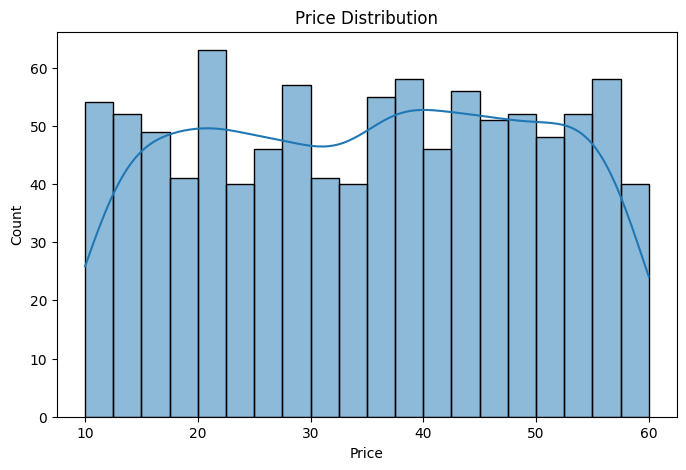

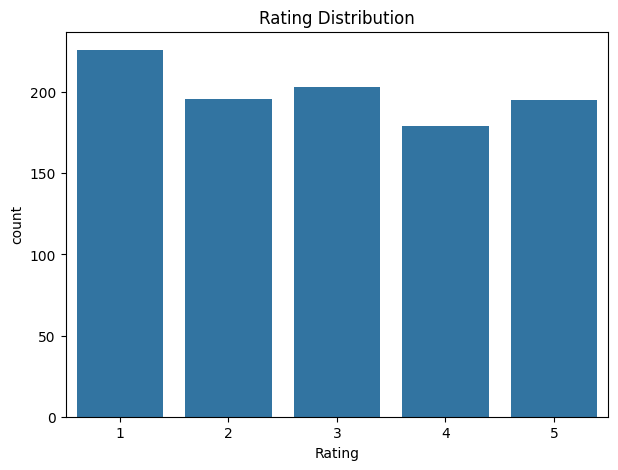

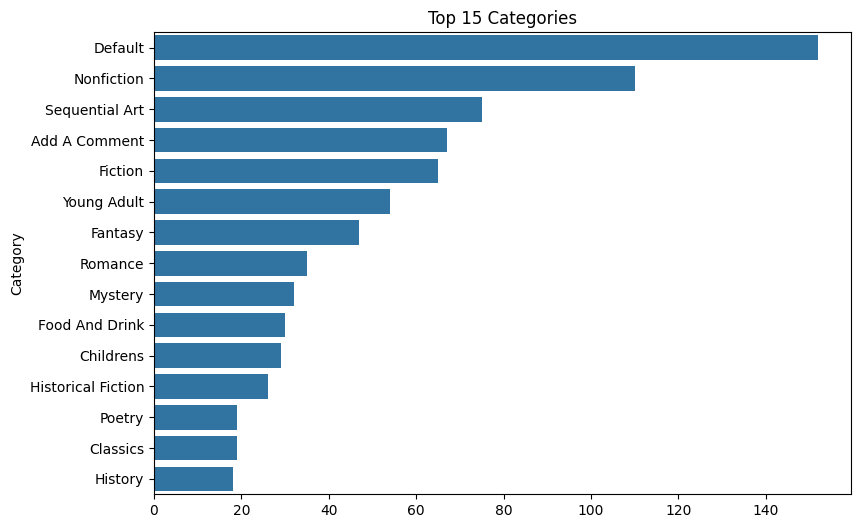

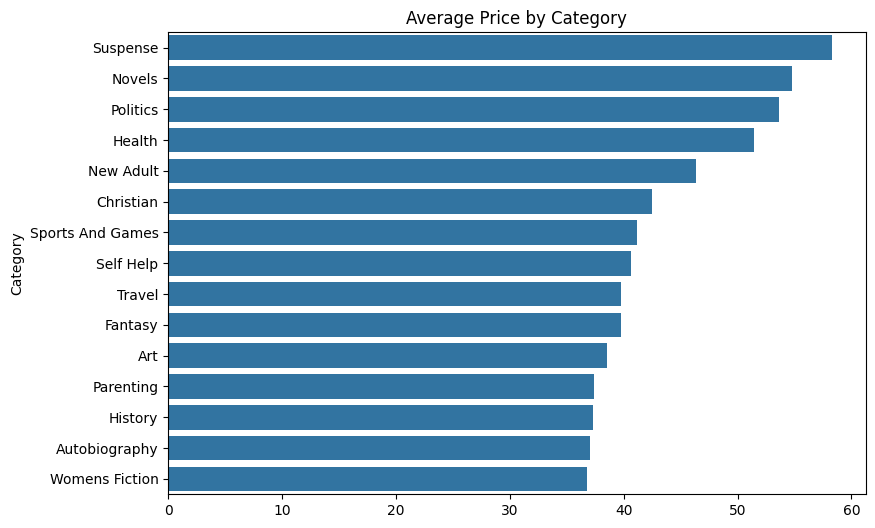

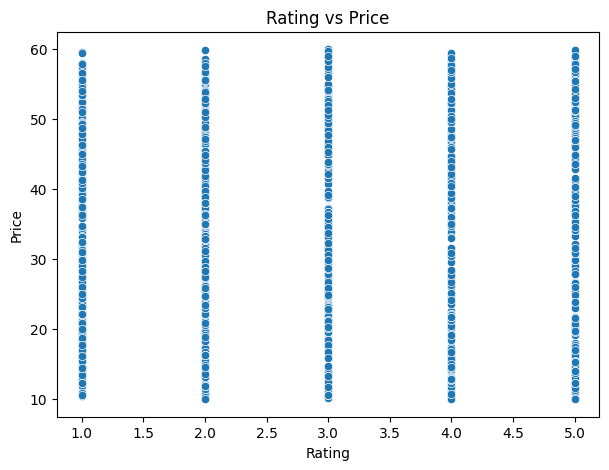

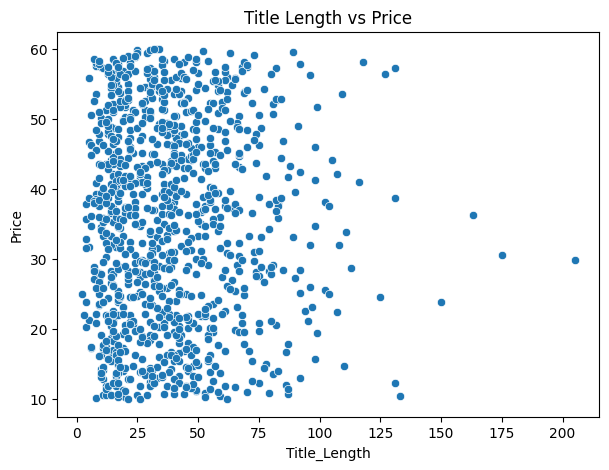

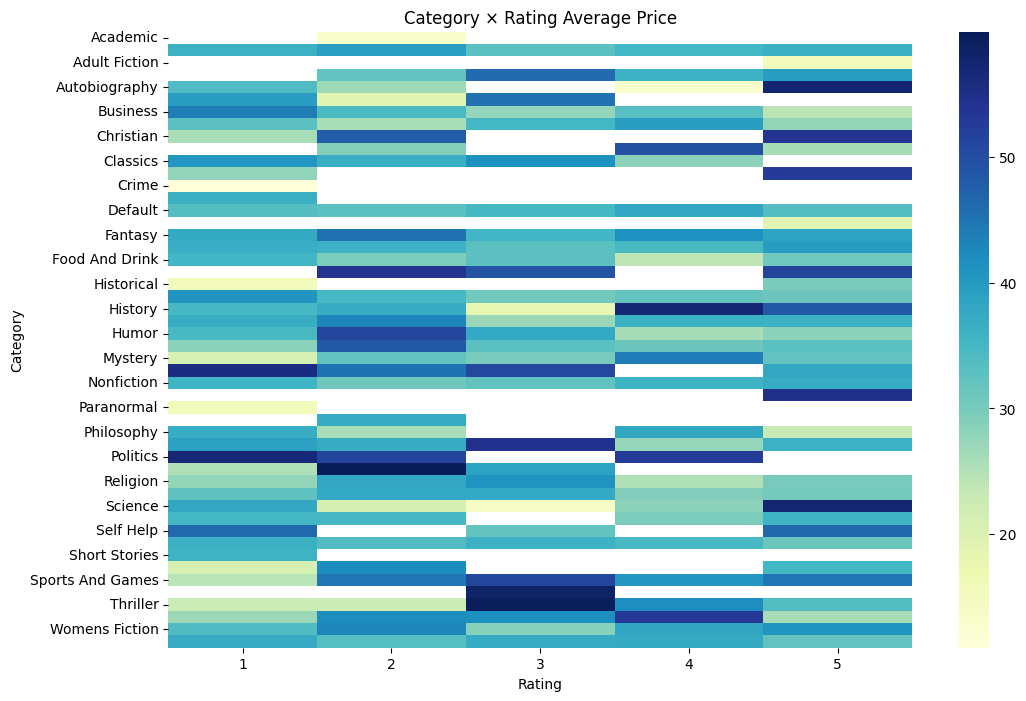

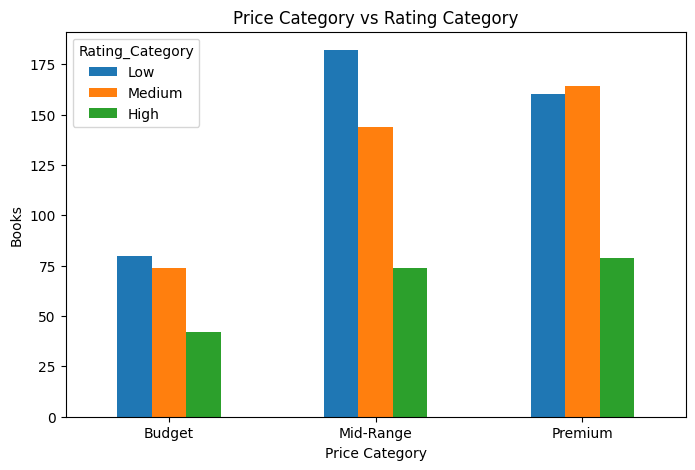

In [8]:
# 1 Univariate
plt.figure(figsize=(8,5)); sns.histplot(df["Price"],bins=20,kde=True); plt.title("Price Distribution"); plt.show()

# 2 Univariate
plt.figure(figsize=(7,5)); sns.countplot(data=df,x="Rating",order=sorted(df["Rating"].dropna().unique())); plt.title("Rating Distribution"); plt.show()

# 3 Univariate
top=df["Category"].value_counts().head(15); plt.figure(figsize=(9,6)); sns.barplot(x=top.values,y=top.index); plt.title("Top 15 Categories"); plt.show()

# 4 Bivariate
avg=df.groupby("Category")["Price"].mean().sort_values(ascending=False).head(15); plt.figure(figsize=(9,6)); sns.barplot(x=avg.values,y=avg.index); plt.title("Average Price by Category"); plt.show()

# 5 Bivariate
plt.figure(figsize=(7,5)); sns.scatterplot(data=df,x="Rating",y="Price"); plt.title("Rating vs Price"); plt.show()

# 6 Bivariate
plt.figure(figsize=(7,5)); sns.scatterplot(data=df,x="Title_Length",y="Price"); plt.title("Title Length vs Price"); plt.show()

# 7 Multivariate
heat=pd.pivot_table(df,index="Category",columns="Rating",values="Price",aggfunc="mean")
plt.figure(figsize=(12,8)); sns.heatmap(heat,cmap="YlGnBu"); plt.title("Category × Rating Average Price"); plt.show()

# 8 Multivariate
ct=pd.crosstab(df["Price_Category"],df["Rating_Category"])
ct.plot(kind="bar",figsize=(8,5)); plt.title("Price Category vs Rating Category"); plt.xlabel("Price Category"); plt.ylabel("Books"); plt.xticks(rotation=0); plt.show()

# **8.Ten Business Questions**

In [9]:
questions={
"Q1 Highest average price categories":df.groupby("Category")["Price"].mean().sort_values(ascending=False).head(10),
"Q2 Most affordable categories":df.groupby("Category")["Price"].mean().sort_values().head(10),
"Q3 Highest-rated books":df.sort_values(["Rating","Price"],ascending=[False,False])[["Title","Rating","Price"]].head(10),
"Q4 Average price by rating":df.groupby("Rating")["Price"].mean(),
"Q5 Price-rating correlation":df[["Price","Rating"]].corr().loc["Price","Rating"],
"Q6 Price-category distribution":df["Price_Category"].value_counts(),
"Q7 Largest catalogue categories":df["Category"].value_counts().head(10),
"Q8 Ten most expensive books":df.nlargest(10,"Price")[["Title","Category","Price","Rating"]],
"Q9 Average price by rating group":df.groupby("Rating_Category",observed=False)["Price"].mean(),
"Q10 Highest average rating categories":df.groupby("Category")["Rating"].mean().sort_values(ascending=False).head(10)
}
for q,a in questions.items():
    print("\n"+q); display(a)


Q1 Highest average price categories


,Price
Category,
Suspense,58.330000
Novels,54.810000
Politics,53.613333
Health,51.452500
New Adult,46.383333
Christian,42.496667
Sports And Games,41.166000
Self Help,40.620000
Travel,39.794545



Q2 Most affordable categories


,Price
Category,
Crime,10.970000
Academic,13.120000
Adult Fiction,15.360000
Paranormal,15.400000
Erotica,19.190000
Historical,22.830000
Food And Drink,31.414667
Thriller,31.433636
Mystery,31.719062



Q3 Highest-rated books


...

,Title,Category,Price,Rating
648,The Perfect Play (Play by Play #1),Romance,59.99,3
617,Last One Home (New Beginnings #1),Fiction,59.98,3
860,Civilization and Its Discontents,Psychology,59.95,2
560,The Barefoot Contessa Cookbook,Food And Drink,59.92,5
366,The Diary of a Young Girl,Nonfiction,59.90,3
657,The Bone Hunters (Lexy Vaughan & Steven Macaul...,Thriller,59.71,3
133,Thomas Jefferson and the Tripoli Pirates: The ...,History,59.64,1
387,Boar Island (Anna Pigeon #19),Mystery,59.48,3
393,The Improbability of Love,Fiction,59.45,1
549,The Man Who Mistook His Wife for a Hat and Oth...,Nonfiction,59.45,4



Q9 Average price by rating group


,Price
Rating_Category,
Low,34.677180
Medium,35.348639
High,35.390256



Q10 Highest average rating categories


,Rating
Category,
Erotica,5.000000
Adult Fiction,5.000000
Novels,5.000000
Christian Fiction,4.166667
Health,3.750000
Art,3.625000
Poetry,3.526316
Humor,3.400000
Spirituality,3.333333


# **9.Eight Insights**

In [10]:
corr=df[["Price","Rating"]].corr().loc["Price","Rating"]
insights=[
f"Highest average-price category: {df.groupby('Category')['Price'].mean().idxmax()}.",
f"Lowest average-price category: {df.groupby('Category')['Price'].mean().idxmin()}.",
f"Largest catalogue category: {df['Category'].value_counts().idxmax()}.",
f"Most common rating: {int(df['Rating'].mode().iloc[0])} stars.",
f"Median listed price: £{df['Price'].median():.2f}.",
f"Books priced at £40 or above: {(df['Price']>=40).mean()*100:.1f}%.",
f"Highest average-rating category: {df.groupby('Category')['Rating'].mean().idxmax()}.",
f"Price-rating correlation: {corr:.2f}; price alone should not be used as a quality proxy."
]
for i,x in enumerate(insights,1): print(f"{i}. {x}")

1. Highest average-price category: Suspense.
2. Lowest average-price category: Crime.
3. Largest catalogue category: Default.
4. Most common rating: 1 stars.
5. Median listed price: £36.00.
6. Books priced at £40 or above: 40.3%.
7. Highest average-rating category: Adult Fiction.
8. Price-rating correlation: 0.03; price alone should not be used as a quality proxy.


# **10. Five Actionable Recommendations**

1. Use category-based pricing and merchandising.
2. Promote highly rated books in recommendation and featured sections.
3. Create budget and premium sections to simplify catalogue navigation.
4. Review catalogue assortment in categories with unusually high/low representation.
5. Combine price, rating and category rather than using price alone as a quality indicator.